<a href="https://colab.research.google.com/github/bfs0/SDAIA_Athkax_A-B_Testing_PROJECT/blob/main/Copy_of_%D8%AA%D9%85%D8%B1%D9%8A%D9%86_3_1%D8%8C_%D8%A7%D9%84%D8%A7%D8%B7%D9%84%D8%A7%D8%B9_%D8%A7%D9%84%D9%85%D8%A8%D9%83%D8%B1_%D9%88%D8%AD%D8%AF%D9%88%D8%AF_O'Brien_Fleming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# تمرين 3.1: الاطلاع المبكر وحدود O'Brien-Fleming

**برنامج التجارب واختبارات A/B والاستدلال السببي**، اليوم الثالث

**الخطوات:**
1. من قائمة File اختر Save a copy in Drive، واعمل على النسخة التي تُفتح.
2. شغّل الخلايا بالترتيب، ثم اكتب حلك في الخلية المخصصة.
3. اضغط Share، واجعل General access على Anyone with the link بصلاحية Viewer، ثم اضغط Copy link.
4. الصق الرابط في ملف التقييم الخاص بمجموعتك، في عمود «تمرين 3.1».

</div>

<div dir="rtl">

## الإعداد

شغّل الخلية التالية أولًا.

</div>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from sklearn.neighbors import NearestNeighbors


def tidy(fit, terms=None):
    """جدول مختصر لنتيجة الانحدار."""
    ci = fit.conf_int()
    out = pd.DataFrame({"المعامل": fit.params, "SE": fit.bse, "أدنى 95%": ci[0], "أعلى 95%": ci[1], "p": fit.pvalues})
    return out.loc[terms] if terms else out


def smd(x, group):
    """الفرق المعياري بين متوسطي مجموعتين."""
    x, group = np.asarray(x, dtype=float), np.asarray(group)
    a, b = x[group == 1], x[group == 0]
    return (a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)


say("الإعداد جاهز")

<div dir="rtl">

## الأدوات الجاهزة

هذه الدوال والبيانات من دفتر اليوم، ويحتاجها التمرين. شغّلها كما هي.

</div>

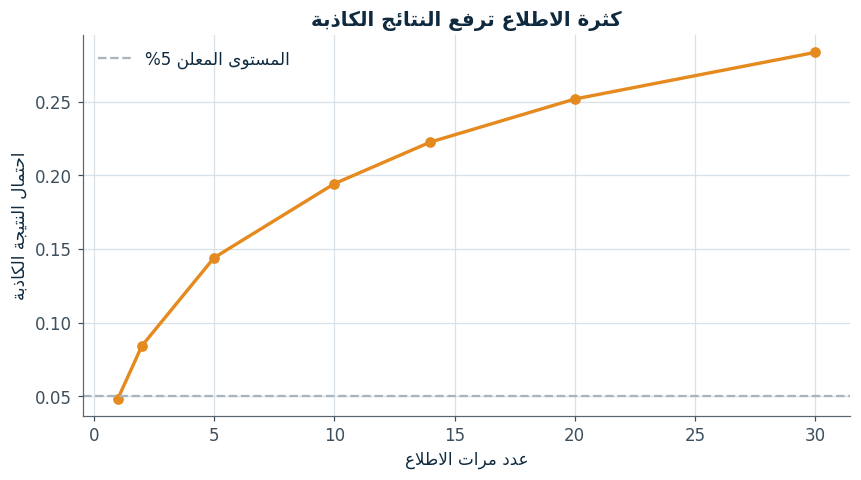

,عدد مرات الاطلاع,احتمال النتيجة الكاذبة
0,1,0.0482
1,2,0.0842
2,5,0.1439
3,10,0.1942
4,14,0.2225
5,20,0.2517
6,30,0.2833


In [2]:
def peeking_fpr(looks, sims=20_000, alpha=0.05, seed=0):
    """تجارب بدون أي أثر: ننظر إلى النتيجة عدة مرات ونوقف عند أول نتيجة دالة."""
    r = np.random.default_rng(seed)
    z_path = np.cumsum(r.standard_normal((sims, looks)), axis=1) / np.sqrt(np.arange(1, looks + 1))
    return np.mean((np.abs(z_path) > stats.norm.ppf(1 - alpha / 2)).any(axis=1))


looks_list = [1, 2, 5, 10, 14, 20, 30]
peek_table = pd.DataFrame({"عدد مرات الاطلاع": looks_list,
                           "احتمال النتيجة الكاذبة": [peeking_fpr(k) for k in looks_list]})
plt.plot(peek_table.iloc[:, 0], peek_table.iloc[:, 1], marker="o", color=ORANGE, linewidth=2.2)
plt.axhline(0.05, color=GRAY, linestyle="--", label=ar("المستوى المعلن 5%"))
plt.xlabel(ar("عدد مرات الاطلاع"))
plt.ylabel(ar("احتمال النتيجة الكاذبة"))
plt.title(ar("كثرة الاطلاع ترفع النتائج الكاذبة"))
plt.legend()
plt.show()
peek_table

In [3]:
def obf_constant(looks, alpha=0.05, sims=200_000, seed=1):
    """نبحث عن قيمة c التي تجعل احتمال النتيجة الكاذبة الكلي يساوي alpha."""
    r = np.random.default_rng(seed)
    z_path = np.cumsum(r.standard_normal((sims, looks)), axis=1) / np.sqrt(np.arange(1, looks + 1))
    scale = np.sqrt(looks / np.arange(1, looks + 1))
    lo, hi = 1.5, 4.0
    for _ in range(40):
        c = (lo + hi) / 2
        fpr = np.mean((np.abs(z_path) > c * scale).any(axis=1))
        lo, hi = (c, hi) if fpr > alpha else (lo, c)
    return (lo + hi) / 2


K = 10
c = obf_constant(K)
bounds = c * np.sqrt(K / np.arange(1, K + 1))

r = np.random.default_rng(99)
z_check = np.cumsum(r.standard_normal((50_000, K)), axis=1) / np.sqrt(np.arange(1, K + 1))
say(f"ثابت O'Brien-Fleming عند {K} نظرات يساوي تقريبًا {c:.3f}")
say(f"احتمال النتيجة الكاذبة مع هذه الحدود: {np.mean((np.abs(z_check) > bounds).any(axis=1)):.1%}")
pd.DataFrame({"النظرة": range(1, K + 1), "حد z المطلوب": bounds.round(2)}).set_index("النظرة").T

النظرة,1,2,3,4,5,6,7,8,9,10
حد z المطلوب,6.58,4.65,3.8,3.29,2.94,2.69,2.49,2.33,2.19,2.08


<div dir="rtl">

## المطلوب

فريق يريد الاطلاع على نتائج تجربته **مرة كل أسبوع لمدة 4 أسابيع**.
1. ما احتمال النتيجة الكاذبة إذا استخدم الحد 1.96 في كل مرة؟
2. احسب حدود O'Brien-Fleming للنظرات الأربع.

</div>

In [13]:
# اكتب حلك هنا
# استخدم الدالتين peeking_fpr و obf_constant
a = peeking_fpr(4);#اربع اسابيع مره كل اسبوع
print("احتمال النتيجة الكاذبة : " , a )

K = 4
c = obf_constant(K)
bounds = c * np.sqrt(K / np.arange(1, K + 1))

r = np.random.default_rng(99)
z_check = np.cumsum(r.standard_normal((50_000, K)), axis=1) / np.sqrt(np.arange(1, K + 1))
say(f"ثابت O'Brien-Fleming عند {K} نظرات يساوي تقريبًا {c:.3f}")
say(f"احتمال النتيجة الكاذبة مع هذه الحدود: {np.mean((np.abs(z_check) > bounds).any(axis=1)):.1%}")
pd.DataFrame({"النظرة": range(1, K + 1), "حد z المطلوب": bounds.round(2)}).set_index("النظرة").T

احتمال النتيجة الكاذبة :  0.1261


النظرة,1,2,3,4
حد z المطلوب,4.04,2.86,2.33,2.02


<div dir="rtl">

## التسليم

انتهيت؟ اضغط Share، ثم Copy link، والصق الرابط في ملف التقييم في عمود «تمرين 3.1».

</div>